# 02 · Feature preprocessing & engineering

How raw HMDA columns become model inputs, checks that the features behave as intended, and how much
each feature group contributes.

```
raw HMDA columns (strings)
  └─ HMDAFeatures            row-wise parsing + engineered features   (stateless → can't leak)
      └─ make_preprocessor   impute / encode / scale                  (fit on training rows only)
          └─ model
```

Code: `src/hmda/features.py` (unit tests in `tests/test_features.py`).
Data: 3% sample of 2024 for fitting, 1% sample of 2025 for scoring. Same split logic as the
model-selection notebook.

Sections: 1 column groups · 2 engineered features · 3 univariate signal · 4 encoders ·
5 feature-group ablations · 6 takeaways

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

from hmda.data import REPO_ROOT, approved_vs_denied, load_hmda
from hmda import features as F
from hmda.features import HMDAFeatures, make_pipeline, make_preprocessor, split_xy
from hmda.models import benchmark, model_zoo, score
from hmda import plotting as hp

hp.use_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 120)
REPORTS = REPO_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

## 1. Column groups

In [2]:
groups = {
    "leakage (never used)": F.LEAKAGE_COLS,
    "protected (excluded by default)": F.PROTECTED_COLS,
    "categorical → one-hot / ordinal": F.CATEGORICAL_COLS,
    "high-cardinality ID → target encoding": F.HIGH_CARD_COLS,
    "raw numeric": F.RAW_NUMERIC_COLS,
    "engineered numeric": F.ENGINEERED_NUMERIC_COLS,
}
pd.DataFrame({"n": {k: len(v) for k, v in groups.items()},
              "columns": {k: ", ".join(v) for k, v in groups.items()}})

,n,columns
leakage (never used),16,"action_taken, purchaser_type, hoepa_status, preapproval, initially_payable_to_institution, interest_rate, rate_sprea..."
protected (excluded by default),35,"derived_ethnicity, derived_race, derived_sex, applicant_ethnicity_1, applicant_ethnicity_2, applicant_ethnicity_3, a..."
categorical → one-hot / ordinal,21,"state_code, loan_type, loan_purpose, lien_status, occupancy_type, construction_method, conforming_loan_limit, derive..."
high-cardinality ID → target encoding,3,"lei, derived_msa_md, county_code"
raw numeric,12,"loan_amount, income, property_value, combined_loan_to_value_ratio, loan_term, tract_population, tract_minority_popul..."
engineered numeric,13,"debt_to_income, log_loan_amount, log_income, log_property_value, loan_to_income, loan_to_value_calc, income_to_area_..."


In [3]:
assert not set(F.RAW_INPUT_COLS) & set(F.LEAKAGE_COLS), "leaky column in inputs"
assert not set(F.RAW_INPUT_COLS) & set(F.PROTECTED_COLS), "protected column in inputs"
print(f"{len(F.RAW_INPUT_COLS)} raw input columns read by HMDAFeatures; none are leaky or protected ✓")

42 raw input columns read by HMDAFeatures; none are leaky or protected ✓


| Engineered feature | Definition | Why |
|---|---|---|
| `debt_to_income` | DTI parsed to a number: bins → midpoints (`<20%`→15, `50%-60%`→55, `>60%`→65), 36–49 exact | DTI is reported as a mix of bins and exact values |
| `log_loan_amount`, `log_income`, `log_property_value` | log transforms; income ≤ 0 → NaN | heavy right skew (helps the linear model) |
| `loan_to_income` | loan ÷ (income × 1000), clipped to [0, 50] | affordability |
| `loan_to_value_calc` | loan ÷ property value × 100 | fills in when CLTV is missing/exempt |
| `income_to_area_median` | income ÷ MSA median family income | income relative to local cost of living |
| `total_units_n` | unit-count bins → numbers | ordinal |
| `has_coapplicant` | co-applicant credit score type ≠ 10 ("no co-applicant") | two incomes |
| `n_aus` | number of automated underwriting systems used | more AUS runs ≈ harder file |
| `exempt_reporter` | lender reports `1111`/Exempt codes | small lenders with partial exemption |
| `income_nonpositive` | income ≤ 0 | 94% denial rate in EDA |
| `owner_occupied_share` | tract owner-occupied ÷ 1–4 family homes | neighborhood tenure |

## 2. Engineered features on real data

In [4]:
cols = HMDAFeatures().input_cols()
train = approved_vs_denied(load_hmda(years=[2024], actions=[1, 2, 3], columns=cols, sample=0.03))
test = approved_vs_denied(load_hmda(years=[2025], actions=[1, 2, 3], columns=cols, sample=0.01))
X_tr, y_tr = split_xy(train)
X_te, y_te = split_xy(test)
print(f"train (2024): {len(X_tr):,} rows, denial rate {y_tr.mean():.3f}")
print(f"test  (2025): {len(X_te):,} rows, denial rate {y_te.mean():.3f}")

feat = HMDAFeatures()
Ftr, Fte = feat.transform(X_tr), feat.transform(X_te)
num_cols = feat.numeric_cols()
summary = Ftr[num_cols].describe(percentiles=[.01, .5, .99]).T
summary.insert(0, "missing_%", 100 * Ftr[num_cols].isna().mean())
summary.drop(columns=["count", "std"]).round(3)

train (2024): 259,480 rows, denial rate 0.245
test  (2025): 94,006 rows, denial rate 0.227


,missing_%,mean,min,1%,50%,99%,max
loan_amount,0.0000,"298,153.0750","5,000.0000","15,000.0000","205,000.0000","1,455,000.0000","945,505,000.0000"
income,6.3440,224.7270,"-1,871.0000",0.0000,104.0000,801.0000,"17,399,830.0000"
property_value,6.5900,"552,335.6410","5,000.0000","65,000.0000","385,000.0000","2,605,000.0000","1,312,715,000.0000"
combined_loan_to_value_ratio,10.4690,73.1540,0.0020,9.2300,78.4950,104.9200,500.0000
loan_term,4.7360,318.5130,1.0000,12.0000,360.0000,480.0000,"3,000.0000"
tract_population,0.0000,"4,760.7350",0.0000,0.0000,"4,520.0000","11,791.0000","30,199.0000"
tract_minority_population_percent,0.0000,36.2810,0.0000,0.0000,29.0100,98.0700,100.0000
ffiec_msa_md_median_family_income,0.0000,"99,290.5720",0.0000,"26,900.0000","98,200.0000","164,200.0000","201,300.0000"
tract_to_msa_income_percentage,0.0000,108.5250,0.0000,0.0000,104.0000,242.0000,516.0000
tract_owner_occupied_units,0.0000,"1,217.1050",0.0000,0.0000,"1,169.0000","2,804.0000","6,276.0000"


In [5]:
assert np.isfinite(Ftr[num_cols].fillna(0).to_numpy()).all(), "inf values in numeric features"
cat_cols = feat.categorical_cols() + F.HIGH_CARD_COLS
assert not Ftr[cat_cols].isna().any().any(), "categoricals should have an explicit 'NA' level"
print("no inf values; categoricals have no nulls ✓")
print("\nDTI parsing check (raw code → parsed value, share of rows):")
(pd.DataFrame({"raw": X_tr["debt_to_income_ratio"].fillna("<missing>"), "parsed": Ftr["debt_to_income"]})
   .value_counts(dropna=False, normalize=True).head(12).rename("share").to_frame())

no inf values; categoricals have no nulls ✓

DTI parsing check (raw code → parsed value, share of rows):


,,share
raw,parsed,
30%-<36%,33.0000,0.1239
20%-<30%,25.0000,0.1203
50%-60%,55.0000,0.0936
<missing>,NaN,0.0806
>60%,65.0000,0.0701
<20%,15.0000,0.0527
49,49.0000,0.0442
44,44.0000,0.0367
42,42.0000,0.0354


## 3. Univariate signal: raw vs engineered

Each numeric feature's predictive power **on its own**: bin it into 20 quantile bins on 2024
(plus a "missing" bin), use each bin's 2024 denial rate as the score, then compute ROC-AUC on 2025.
This handles non-monotonic shapes such as the U-shaped CLTV curve and counts missingness as signal.

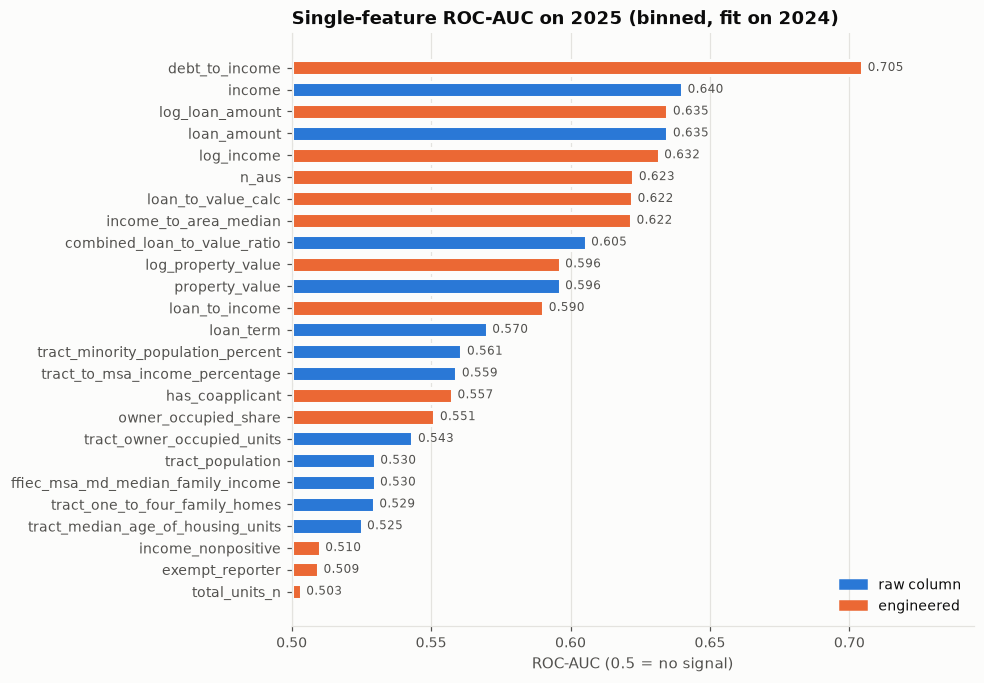

In [6]:
def univariate_auc(col, n_bins=20):
    tr, te = Ftr[col], Fte[col]
    if tr.nunique() <= n_bins:                       # flags / few distinct values: one bin per value
        bin_tr, bin_te = tr.fillna(-1e9).to_numpy(), te.fillna(-1e9).to_numpy()
    else:
        edges = np.unique(np.nanquantile(tr, np.linspace(0, 1, n_bins + 1)))
        bin_tr = np.where(tr.isna(), -1, np.clip(np.searchsorted(edges, tr, side="right"), 1, len(edges) - 1))
        bin_te = np.where(te.isna(), -1, np.clip(np.searchsorted(edges, te, side="right"), 1, len(edges) - 1))
    rate = pd.Series(y_tr).groupby(bin_tr).mean()
    score_te = pd.Series(bin_te).map(rate).fillna(y_tr.mean())
    return roc_auc_score(y_te, score_te)

uni = pd.DataFrame({
    "univariate_auc": {c: univariate_auc(c) for c in num_cols},
    "kind": {c: "engineered" if c in F.ENGINEERED_NUMERIC_COLS else "raw" for c in num_cols},
}).sort_values("univariate_auc", ascending=False)
uni.to_csv(REPORTS / "univariate_auc.csv")

fig, ax = plt.subplots(figsize=(8, 7))
colors = [hp.ORANGE if k == "engineered" else hp.BLUE for k in uni["kind"]]
ax.barh(range(len(uni)), uni["univariate_auc"] - 0.5, left=0.5, color=colors, height=0.7,
        edgecolor=hp.SURFACE, linewidth=2)
ax.set_yticks(range(len(uni)), uni.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for i, v in enumerate(uni["univariate_auc"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=hp.TEXT_SECONDARY)
ax.set_xlim(0.5, uni["univariate_auc"].max() + 0.04)
ax.set(title="Single-feature ROC-AUC on 2025 (binned, fit on 2024)", xlabel="ROC-AUC (0.5 = no signal)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=hp.BLUE, label="raw column"), Patch(color=hp.ORANGE, label="engineered")],
          loc="lower right")
plt.show()

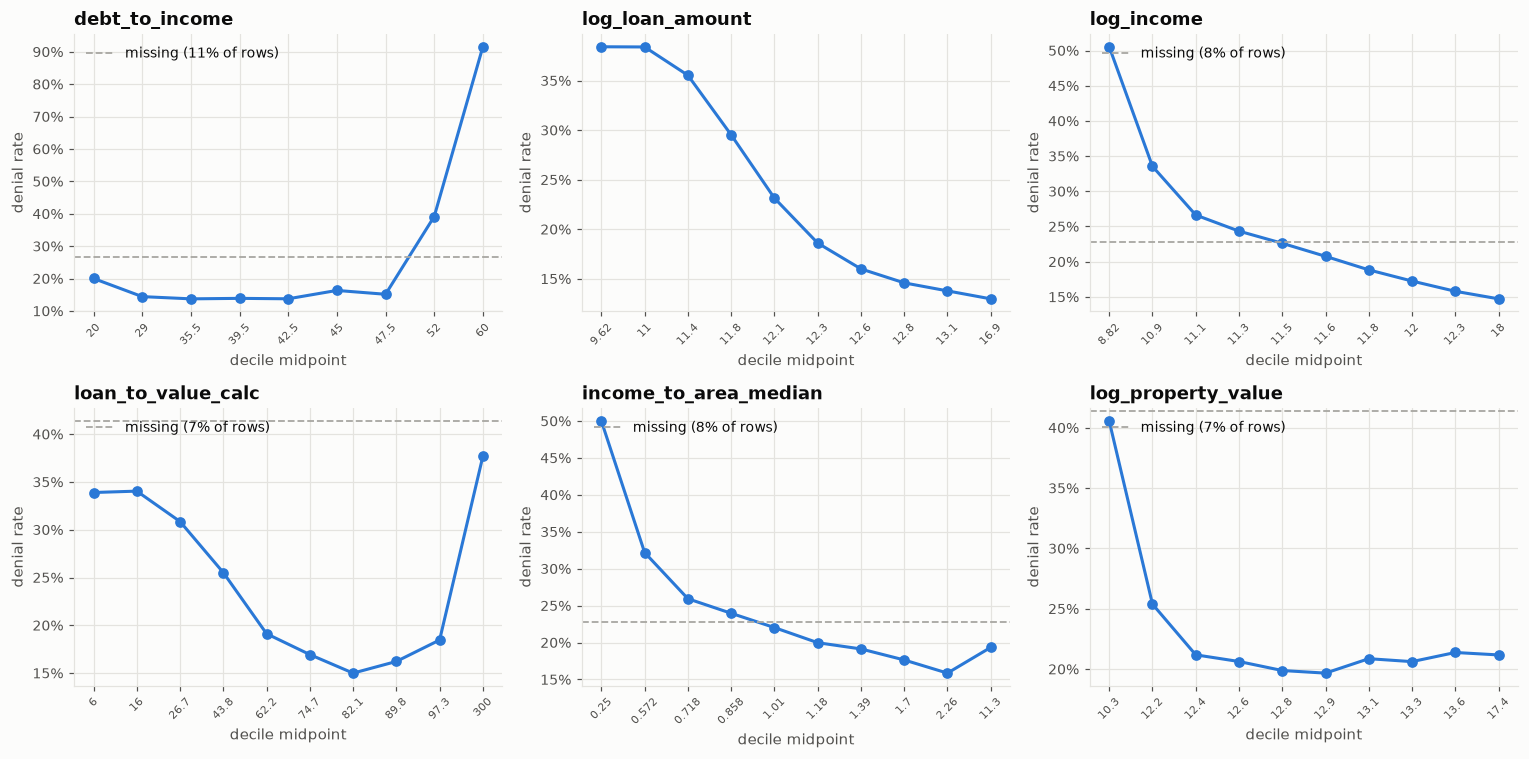

In [7]:
# denial rate across deciles for the top engineered features
show = [c for c in uni.index if c in F.ENGINEERED_NUMERIC_COLS and Ftr[c].nunique() > 10][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, show):
    q = pd.qcut(Ftr[c], 10, duplicates="drop")
    d = pd.DataFrame({"bin": q, "y": y_tr}).groupby("bin", observed=True)["y"].agg(["mean", "size"])
    mids = [iv.mid for iv in d.index]
    ax.plot(range(len(d)), d["mean"], marker="o", color=hp.BLUE)
    miss = y_tr[Ftr[c].isna().to_numpy()]
    if len(miss) > 100:
        ax.axhline(miss.mean(), color=hp.MUTED, lw=1.2, ls="--", label=f"missing ({len(miss)/len(y_tr):.0%} of rows)")
        ax.legend(loc="upper left")
    ax.set_xticks(range(len(d)), [f"{m:.3g}" for m in mids], rotation=45, fontsize=7)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set(title=c, xlabel="decile midpoint", ylabel="denial rate")
fig.tight_layout(); plt.show()

## 4. Encoders: what each model actually sees

In [8]:
rows = []
for kind in ["linear", "tree"]:
    prep = make_preprocessor(kind)
    Xt = prep.fit_transform(Ftr, y_tr)
    rows.append({"kind": kind, "output_columns": Xt.shape[1], "any_NaN": bool(Xt.isna().any().any()),
                 "groups": ", ".join(f"{n}: {len(c)} in" for n, _, c in prep.transformers)})
    if kind == "linear":
        Xt_lin = Xt
    else:
        Xt_tree = Xt
pd.DataFrame(rows).set_index("kind")

,output_columns,any_NaN,groups
kind,,,
linear,190,False,"num: 25 in, cat: 21 in, te: 3 in, freq: 1 in"
tree,50,True,"num: 25 in, cat: 21 in, te: 3 in, freq: 1 in"


lenders in train sample: 4,424; correlation of encoding with in-sample lender denial rate (lenders with 200+ rows): 1.000


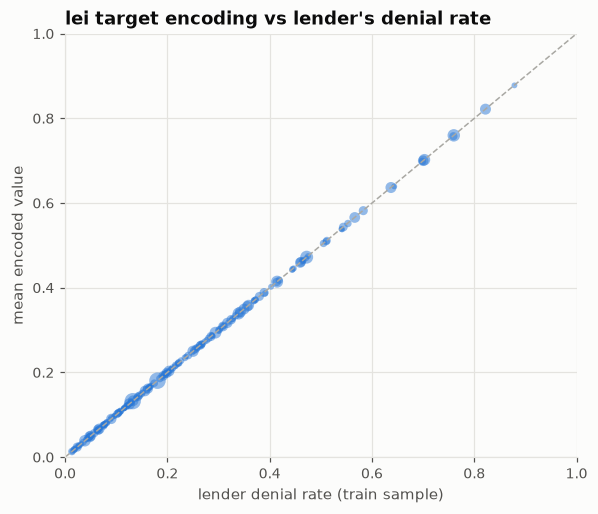

In [9]:
# Target encoding of lender (lei): cross-fitted on train, so each row's value excludes its own fold.
lender_rate = pd.Series(y_tr).groupby(Ftr["lei"].to_numpy()).agg(["mean", "size"])
te_vals = pd.DataFrame({"lei": Ftr["lei"].to_numpy(), "encoded": Xt_tree["lei"].to_numpy()})
cmp = te_vals.groupby("lei")["encoded"].mean().to_frame().join(lender_rate)
big = cmp[cmp["size"] >= 200]
print(f"lenders in train sample: {len(cmp):,}; correlation of encoding with in-sample lender denial rate "
      f"(lenders with 200+ rows): {np.corrcoef(big['encoded'], big['mean'])[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(big["mean"], big["encoded"], s=np.sqrt(big["size"]), alpha=0.5, color=hp.BLUE, linewidths=0)
ax.plot([0, 1], [0, 1], color=hp.MUTED, lw=1, ls="--")
ax.set(title="lei target encoding vs lender's denial rate", xlabel="lender denial rate (train sample)",
       ylabel="mean encoded value", xlim=(0, 1), ylim=(0, 1))
plt.show()

## 5. Feature-group ablations (LightGBM)

Same model and data, removing one group at a time (fit 2024 sample, score 2025 sample):

* **no DTI:** DTI only exists after parsing (`debt_to_income`), so this measures that single feature.
* **no engineered features (keeps parsed DTI):** drops the ratios, logs, and flags. Is the rest of the
  feature engineering pulling its weight?
* **no lender ID:** lender identity was a top feature in the EDA. How much of the model is
  "which lender they applied to"?
* **no lender / MSA / county IDs:** all target-encoded IDs removed.
* **+ protected attributes:** race, ethnicity, sex, and age added. This is analysis only, not deployable.
* **LEAKY:** a model given *only* post-decision fields, to show why they're excluded.

In [10]:
lgbm = {"LightGBM": model_zoo()["LightGBM"]}
abl = {}
for label, kw in [("default (all features)", {}),
                  ("no DTI", {"drop": ["debt_to_income"]}),
                  ("no engineered features (keeps parsed DTI)",
                   {"drop": [c for c in F.ENGINEERED_NUMERIC_COLS if c != "debt_to_income"]}),
                  ("no lender ID", {"drop": ["lei"]}),
                  ("no lender / MSA / county IDs", {"drop": ["lei", "derived_msa_md", "county_code"]})]:
    res, _ = benchmark(lgbm, X_tr, y_tr, X_te, y_te, verbose=False, **kw)
    abl[label] = res.iloc[0]

cols_p = HMDAFeatures(include_protected=True).input_cols()
tr_p = approved_vs_denied(load_hmda(years=[2024], actions=[1, 2, 3], columns=cols_p, sample=0.03))
te_p = approved_vs_denied(load_hmda(years=[2025], actions=[1, 2, 3], columns=cols_p, sample=0.01))
res, _ = benchmark(lgbm, *split_xy(tr_p, True), *split_xy(te_p, True), include_protected=True, verbose=False)
abl["+ protected attributes"] = res.iloc[0]

leak_cols = ["interest_rate", "rate_spread", "total_loan_costs", "origination_charges",
             "purchaser_type", "hoepa_status"]
def leak_xy(year, frac):
    d = approved_vs_denied(load_hmda(years=[year], actions=[1, 2, 3], columns=leak_cols, sample=frac))
    return d[leak_cols].apply(pd.to_numeric, errors="coerce"), d["denied"].to_numpy()
Xl_tr, yl_tr = leak_xy(2024, 0.03)
Xl_te, yl_te = leak_xy(2025, 0.01)
leak = LGBMClassifier(n_estimators=100, verbose=-1).fit(Xl_tr, yl_tr)
abl["LEAKY: post-decision fields only"] = pd.Series(score(yl_te, leak.predict_proba(Xl_te)[:, 1]))

abl = pd.DataFrame(abl).T[["roc_auc", "pr_auc", "log_loss", "f1"]]
abl["auc_vs_default"] = abl["roc_auc"] - abl.loc["default (all features)", "roc_auc"]
abl.to_csv(REPORTS / "feature_ablations.csv")
abl

,roc_auc,pr_auc,log_loss,f1,auc_vs_default
default (all features),0.8998,0.8162,0.2914,0.7107,0.0000
no DTI,0.8700,0.7477,0.3406,0.6292,-0.0298
no engineered features (keeps parsed DTI),0.8976,0.8126,0.2943,0.7038,-0.0022
no lender ID,0.8807,0.7856,0.3161,0.6847,-0.0191
no lender / MSA / county IDs,0.8808,0.7862,0.3157,0.6859,-0.0190
+ protected attributes,0.9010,0.8169,0.2906,0.7123,0.0013
LEAKY: post-decision fields only,0.9940,0.9606,0.0393,0.9799,0.0942


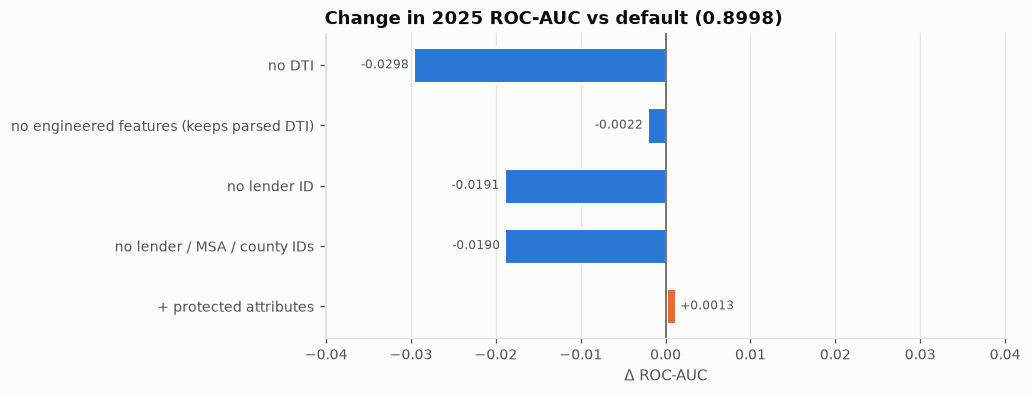

In [11]:
# leaky row left out of the chart (its +0.1 would dwarf the rest); see table above
d = abl.drop(index=["default (all features)", "LEAKY: post-decision fields only"])
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [hp.ORANGE if v > 0 else hp.BLUE for v in d["auc_vs_default"]]
ax.barh(range(len(d)), d["auc_vs_default"], color=colors, height=0.6, edgecolor=hp.SURFACE, linewidth=2)
ax.set_yticks(range(len(d)), d.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.axvline(0, color=hp.TEXT_SECONDARY, lw=1)
for i, v in enumerate(d["auc_vs_default"]):
    ax.text(v, i, f" {v:+.4f}" if v >= 0 else f"{v:+.4f} ", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=hp.TEXT_SECONDARY)
lim = d["auc_vs_default"].abs().max() * 1.35
ax.set_xlim(-lim, lim)
ax.set(title=f"Change in 2025 ROC-AUC vs default ({abl.loc['default (all features)', 'roc_auc']:.4f})",
       xlabel="Δ ROC-AUC")
plt.show()

## 6. Takeaways

Results from fitting on a 3% sample of 2024 (259k rows) and scoring a 1% sample of 2025 (94k rows):

* **Leakage guard holds:** the 42 raw input columns contain no leaky or protected fields. A model
  given *only* post-decision fields scores **0.994 AUC**, which is what including them would have faked.
* **Parsing DTI is the single most valuable step.** It's the best single feature (univariate AUC
  **0.705**), and dropping it costs LightGBM **−0.030 AUC** (0.900 → 0.870), the largest drop of any group.
* **The other engineered features add little for trees:** dropping all the ratios, logs, and flags
  (keeping parsed DTI) costs only **−0.002 AUC**, because gradient boosting can learn interactions like
  loan ÷ income on its own. They're kept because they're cheap, make the feature-importance results
  easier to read, and matter more for linear models.
  Several are individually strong (`n_aus` 0.623, `loan_to_value_calc` 0.622, `income_to_area_median` 0.622).
* **Lender identity is worth about 0.019 AUC** (0.900 → 0.881). Removing MSA and county IDs as well changes
  nothing more, so geography IDs add almost nothing once lender is known. Whether to keep `lei` is a
  **modeling decision**: it improves prediction, but part of what it learns is the lender's own policy
  rather than the applicant's risk.
* **Protected attributes add only +0.001 AUC**, so excluding them costs essentially nothing. The other
  features already carry nearly all of that information, which is why the notebook 03 fairness audit
  still matters.
* **Encoders:** the linear pipeline produces 190 columns with no NaNs (imputed, with missing indicators);
  the tree pipeline produces 50 columns and leaves NaNs for the models to handle. Missingness carries
  signal: e.g. missing LTV is denied ~41% vs 15–19% in the middle deciles.